**I - ESPAÑA U18**

FECHA:XXXX

ID:XXXX

TENGO QUE IMPORTAR LAS LIBRERIAS necesito para el análisis de los datos del partido las librerias de pandas y numpy. Estas se usan para la manipulacion y calculo de datos. Matplotlib -> se usa para generar las visualizaciones de analisis

In [1]:
#librerias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

necesito instalar con pip la libreria de python-docx -> es para crear y modificar documentos de word que lo usaré luego para formar automaticamente el informe de plantilla

In [2]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 4.4 MB/s eta 0:00:00


Configuracion de herramientas para el informe funciones que permiten crear y dar formato se incluyen herramientas para generar el documento, modificar tamaño , ...etc

In [3]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT

from docx.enum.section import WD_SECTION

la libreria os -> me deja trabajar con el sistema de archivos y gestionar las rutas / carpetas

In [4]:
import os

importanteeee!!! es para conectar con el entorno de google drive y así puedo acceder a los archivos del proyecto

In [5]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Tengo hacer las rutas para las carpetas que contienen los archivos del pbp Y LAS rutas de las diferentes subcarpetas destinadas a guardar la configuracion, los dataset, los graficos,...




In [6]:
from pathlib import Path

# Carpeta con los Play-by-Play originales
CARPETA_PBP = Path("/content/drive/MyDrive/TFG_UGR/FIBA_PlayByPlay")

# Carpeta del proyecto
CARPETA_PROYECTO = Path("/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas")

CARPETA_CONFIG = CARPETA_PROYECTO / "Configuracion_parejas"
CARPETA_DATASET = CARPETA_PROYECTO / "Dataset_parejas"
CARPETA_GRAFICOS = CARPETA_PROYECTO / "Graficos_parejas"
CARPETA_MAPAS = CARPETA_PROYECTO / "Mapas_calor"
CARPETA_INFORMES = CARPETA_PROYECTO / "Informes_parejas"

Cargo el archivo del pbp

In [7]:
archivos_pbp= list(CARPETA_PBP.glob("*.csv"))

print(f"Archivos encontrados: {len(archivos_pbp)}")

for archivo in archivos_pbp:
  print("-", archivo.name)

Archivos encontrados: 9
- pbp_131919.csv
- pbp_131878.csv
- pbp_131881.csv
- pbp_131905.csv
- pbp_131892.csv
- pbp_114393.csv
- pbp_131880.csv
- pbp_131897.csv
- identificacion_C1_Espana_131878.csv


CAMBIAAAAAAR

Cargo los archivo del csv correspondiente al play by play del partido. una vez cargado mediante pandas se comprueba sus dimensiones y hago que se visualicen las primeras filas para verificar que está todo OK

In [8]:
#ruta archivo pbp
ruta_csv="/content/drive/MyDrive/TFG_UGR/FIBA_PlayByPlay/pbp_131897.csv"

#leer el csv
df=pd.read_csv(ruta_csv, encoding="utf- 8 -sig")

#informacion basica
print(df.shape)
display(df.head())

(558, 24)


,Time,GT,SC,SA,SB,AC,Action,ActionOris,SU,Z1,...,C2,SX,SY,Id,PId,SP,ST,STQ,SortOrder,Quarter
0,10:00,1786014077000,0,0,0,STARTG,Start of game,Start of game,NaN,NaN,...,NaN,0,0,1,NaN,0,0,0,1000,Q1
1,10:00,1786014077000,0,0,0,STARTP,Start of period,Start of period,NaN,NaN,...,NaN,0,0,2,NaN,0,0,0,2000,Q1
2,10:00,1786014077000,0,0,0,JS,jump ball situation; throw-in,Alternating possession gained,NaN,NaN,...,NaN,0,0,4,NaN,0,0,0,4000,Q1
3,9:59,1786014078000,0,0,0,JB,jump ball won,Jump ball won,+,NaN,...,NaN,0,0,5,4.0,0,0,0,4001,Q1
4,9:59,1786014078000,0,0,0,JB,jump ball lost,Jump ball lost,-,NaN,...,NaN,0,0,6,4.0,0,0,0,4002,Q1


estudiar columnas z1, z2, z3

tengo que identificar los diferentes valores registrados en cada una de ellas. se eliminan temporalmete los valores nulos y se muestran los valores únicos.

así puedo comprobar como están codificadas las zonas

In [9]:
#valores unicos de z1
print("Z1")
print(sorted(df["Z1"].dropna().unique()))

print("Total: ", df["Z1"].unique())

#valores unicos de z2
print("Z2")
print(sorted(df["Z2"].dropna().unique()))

print("Total: ", df["Z2"].unique())


#valores unicos de z3
print("Z3")
print(sorted(df["Z3"].dropna().unique()))

print("Total: ", df["Z3"].unique())



Z1
['1', '2', 'BP', 'C', 'D', 'DD', 'IC', 'IL', 'ILW', 'IR', 'IRW', 'LB', 'LL', 'O', 'OB', 'P', 'RL', 'RW', 'TR']
Total:  [nan 'RL' 'P' 'C' 'IR' 'D' 'O' 'LL' 'BP' '1' 'LB' 'IL' '2' 'TR' 'IRW' 'IC'
 'OB' 'ILW' 'DD' 'RW']
Z2
['1', '2', 'AL', 'FB', 'FT', 'SC', 'ST', 'TO']
Total:  [nan 'SC' 'TO' 'AL' '1' 'FT' 'FB' '2' 'ST']
Z3
['AL', 'DL', 'FB', 'FT', 'JS', 'LU', 'PJ', 'SC', 'SJ', 'TJ', 'TO']
Total:  [nan 'JS' 'DL' 'LU' 'AL' 'PJ' 'SC' 'FB' 'SJ' 'TJ' 'TO' 'FT']


En la columna action se eliminan las combinaciones duplicadas y se ordenan los resultados. Así puedo interpretar los codigos de las zonas y comprobar que tipos de acciones están asociadas a cada uno

In [10]:
df[["Z3", "Action"]].drop_duplicates().sort_values("Z3")

df[["Z2", "Action"]].drop_duplicates().sort_values("Z2")

df[["Z1", "Action"]].drop_duplicates().sort_values("Z1")

,Z1,Action
502,1,1st free throw made
156,1,1st of 2 free throws missed
552,1,Free throw missed 1 of 2
79,1,1st of 2 free throws made
33,1,1st of 1 free throw missed
...,...,...
31,NaN,Substitution out
32,NaN,Substitution in
128,NaN,End of period
538,NaN,turnover


**ver acciones asociadas** : Z1

¿DONDE? la zona de la pista

engo que analizar individualmente los códigos de z1

que muestre las diferentes acciones del pbp asociadas a él

se interpretará la información en z1 y se verá las zonas relevantes

In [11]:
for codigo in sorted(df["Z1"].dropna().unique()):
    print(f"\n===== Z1 = {codigo} =====")
    print(df[df["Z1"] == codigo]["Action"].unique())


===== Z1 = 1 =====
['1st of 1 free throw missed' '1st of 2 free throws made'
 '1st of 2 free throws missed' '1st free throw made'
 'Free throw missed 1 of 2']

===== Z1 = 2 =====
['2nd of 2 free throws made' '2nd of 2 free throws missed'
 'Free throw made 2 of 2']

===== Z1 = BP =====
['turnover; bad pass']

===== Z1 = C =====
['3pt jump shot from center made' '3pt jump shot from center missed'
 '3pt jump shot made' '3pt jump shot missed']

===== Z1 = D =====
['defensive rebound' 'team defensive rebound']

===== Z1 = DD =====
['turnover; double dribble']

===== Z1 = IC =====
['2PtsFG inside center, jump shot made'
 '2PtsFG inside center, jump shot missed' '2pt step back jump shot missed']

===== Z1 = IL =====
['2pt pullup jump shot missed' '2PtsFG inside left, jump shot made'
 '2PtsFG inside left, jump shot missed']

===== Z1 = ILW =====
['2PtsFG inside left wing, points after turnover, jump shot made']

===== Z1 = IR =====
['2PtsFG inside right, jump shot missed'
 '2PtsFG inside righ

**SIGNIFICADOS**

PUB-> DEBAJO DE ARO/POSTE BAJO

IC: INTERIOR CENTRO

IL: INTERIOR IZQUIERDA

IR: INTERIOR DERECHA

ILW: INTERIOR ALA IZQUIERDA

IRW: INTERIOR ALA DERECHA

LL: TRIPLE ESQUINA IZQUIERDA

LW: TRIPLE ALA IZQUIERDA

RL: TRIPLE ESQUINA DERECHA

RW: TRIPLE ALA DERECHA

**NO VOY A USAR EN MAPAS DE CALOR**

LB : PERDIDAS POR MANEJO DE BALÓN

TR : PASOS

O: REBOTE OFENSIVO

P: FALTA PERSONAL

1,2: TIROS LIBRES

**PARA LA TABLA DE ZONAS**

**BAJO ARO**= PUB

**INTERIOR** = IC +IL +IR +ILW +IRW

**TRIPLE**= LL + LW + RL + RW

**ver z2: ¿cómo se genera la acción?**

In [12]:
for codigo in sorted(df["Z2"].dropna().unique()):
    print(f"\n===== Z2 = {codigo} =====")
    print(df[df["Z2"] == codigo]["Action"].unique())


===== Z2 = 1 =====
['Personal foul; 1 free throw awarded' '1st of 1 free throw missed'
 '1st free throw made']

===== Z2 = 2 =====
['Personal foul; 2 free throws awarded' '1st of 2 free throws made'
 '2nd of 2 free throws made' '2nd of 2 free throws missed'
 '1st of 2 free throws missed' 'Free throw missed 1 of 2'
 'Free throw made 2 of 2']

===== Z2 = AL =====
['layup made']

===== Z2 = FB =====
['layup made' '2pt driving layup made']

===== Z2 = FT =====
['2PtsFG inside paint, points from fastbreak + after turnover, layup made'
 '2PtsFG inside right, points from fastbreak + after turnover, jump shot made'
 '3PtsFG outside right, points from fastbreak + after turnover, jump shot made']

===== Z2 = SC =====
['3pt jump shot missed' 'layup missed'
 '2PtsFG inside left, jump shot made' '2pt jump shot missed' 'layup made'
 '2pt jump shot made']

===== Z2 = ST =====
['layup missed' '3pt step back jump shot made']

===== Z2 = TO =====
['layup missed' 'layup made' '3pt jump shot missed' '3pt

no indica la zona ni el tipo de tiro. Indica el contexto de la acción.

FB: fast breack (contraataque)

TO: puntos tras pérdidas rivar (turnover)

SC: (segunda oportundidad) Second chance

FT: fast break + turnover (contraataque tras recuperación)

st : second chance + turnover

AL : acción con varios contextos

1: tiro libre

2: tiros libres

**ver z3: ¿Cómo termina la acción?**

In [13]:
for codigo in sorted(df["Z3"].dropna().unique()):
    print(f"\n===== Z3 = {codigo} =====")
    print(df[df["Z3"] == codigo]["Action"].unique())


===== Z3 = AL =====
['1st of 1 free throw missed']

===== Z3 = DL =====
['2pt driving layup made']

===== Z3 = FB =====
['1st of 2 free throws missed' '2nd of 2 free throws made'
 '1st of 2 free throws made' '2nd of 2 free throws missed']

===== Z3 = FT =====
['Free throw missed 1 of 2' 'Free throw made 2 of 2']

===== Z3 = JS =====
['3pt jump shot made' '3pt jump shot from center made'
 '2PtsFG inside right, jump shot missed' '3pt jump shot missed'
 '2PtsFG inside left, jump shot made' '3pt jump shot from center missed'
 '2pt jump shot missed' '2PtsFG inside right wing, jump shot missed'
 '2PtsFG inside center, jump shot made'
 '2PtsFG inside right, points from fastbreak + after turnover, jump shot made'
 '2PtsFG inside left wing, points after turnover, jump shot made'
 '2PtsFG inside left, jump shot missed' '2pt jump shot made'
 '2PtsFG inside center, jump shot missed'
 '3PtsFG outside right, points from fastbreak + after turnover, jump shot made']

===== Z3 = LU =====
['layup made'

**¿cómo termina la acción?**

LU: layup

DL: driving Layup

JS: jump shot

HS: hook shot

FA: fadeaway

FL: floater

PJ: pull-up jumpl shot

TJ: turnaround jump shot

AOL: alley-oop layup

**DICCIONARIO DE LOS TERMINOS**

In [14]:
dic_z1 = {

    "PUB": "Bajo aro",

    "IC": "Interior centro",
    "IL": "Interior izquierda",
    "IR": "Interior derecha",

    "ILW": "Interior ala izquierda",
    "IRW": "Interior ala derecha",

    "LL": "Triple esquina izquierda",
    "LW": "Triple ala izquierda",

    "RL": "Triple esquina derecha",
    "RW": "Triple ala derecha"

}

Del z2 solo los que tengo seguros

In [15]:
dic_z2 = {

    "FB": "Transición",

    "TO": "Tras pérdida",

    "SC": "Segunda oportunidad"

}

In [16]:
dic_z3 = {

    "LU": "Layup",

    "DL": "Driving layup",

    "JS": "Jump Shot",

    "HS": "Hook Shot",

    "FA": "Fadeaway",

    "FL": "Floater",

    "PJ": "Pull-up",

    "TJ": "Turnaround",

    "AOL": "Alley-oop"

}

**RECONSTRUCCIÓN DE PAREJAS**

En este bloque se localiza dentro de mi pbp todos los registros a las sustituciones

Filtro la columna Action -> busco las acciones relacionadas con las entradas y con las salidas de las jugadoras

El resultado-> lo almaceno en nuevo conjunto de datos -> reconstruir y ver qué jugadoras se encuentran a la vez en la pista



In [17]:
#Localizar las sustitucioneS

sustituciones = df[
    df["Action"]
    .astype(str)
    .str.contains("sub|sust", case=False, na=False)
].copy()

print("Número de registros de sustitución:", len(sustituciones))

display(sustituciones)

Número de registros de sustitución: 134


,Time,GT,SC,SA,SB,AC,Action,ActionOris,SU,Z1,...,C2,SX,SY,Id,PId,SP,ST,STQ,SortOrder,Quarter
31,7:29,1786014332000,0,2,10,SUBST,Substitution out,Sub-Out,-,NaN,...,NaN,0,0,36,NaN,0,0,0,22000,Q1
32,7:29,1786014332000,0,2,10,SUBST,Substitution in,Sub-In,+,NaN,...,NaN,0,0,37,NaN,0,0,0,23000,Q1
42,6:31,1786014419000,0,2,12,SUBST,Substitution out,Sub-Out,-,NaN,...,NaN,0,0,49,NaN,0,0,0,31000,Q1
43,6:31,1786014419000,0,2,12,SUBST,Substitution in,Sub-In,+,NaN,...,NaN,0,0,50,NaN,0,0,0,32000,Q1
69,3:46,1786014643000,0,6,18,SUBST,Substitution out,Sub-Out,-,NaN,...,NaN,0,0,80,NaN,0,0,0,50000,Q1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527,1:43,1786019756000,0,39,89,SUBST,Substitution in,Sub-In,+,NaN,...,NaN,0,0,660,NaN,0,0,0,491000,Q4
533,1:21,1786019809000,0,39,89,SUBST,Substitution out,Sub-Out,-,NaN,...,NaN,0,0,670,NaN,0,0,0,499000,Q4
534,1:21,1786019809000,0,39,89,SUBST,Substitution out,Sub-Out,-,NaN,...,NaN,0,0,671,NaN,0,0,0,500000,Q4
535,1:21,1786019809000,0,39,89,SUBST,Substitution in,Sub-In,+,NaN,...,NaN,0,0,672,NaN,0,0,0,501000,Q4


In [18]:
#Mostrar una sustitución completa en vertical
print(sustituciones.iloc[0])

Time                      7:29
GT               1786014332000
SC                           0
SA                           2
SB                          10
AC                       SUBST
Action        Substitution out
ActionOris             Sub-Out
SU                           -
Z1                         NaN
Z2                         NaN
Z3                         NaN
T1                        T_83
C1                    P_265533
C2                         NaN
SX                           0
SY                           0
Id                          36
PId                        NaN
SP                           0
ST                           0
STQ                          0
SortOrder                22000
Quarter                     Q1
Name: 31, dtype: object


In [19]:
#mostrar entrada
print(sustituciones[sustituciones["Action"]=="Substitution in"].iloc[0])

Time                     7:29
GT              1786014332000
SC                          0
SA                          2
SB                         10
AC                      SUBST
Action        Substitution in
ActionOris             Sub-In
SU                          +
Z1                        NaN
Z2                        NaN
Z3                        NaN
T1                       T_83
C1                   P_339759
C2                        NaN
SX                          0
SY                          0
Id                         37
PId                       NaN
SP                          0
ST                          0
STQ                         0
SortOrder               23000
Quarter                    Q1
Name: 32, dtype: object


la jugadora está en C1

SU='-' -> sale

SU= '+' -> entra

**IDENTIFICAR EL EQUIPO EN T1, QUIERO SABER QUIEN ES ESPAÑA**

In [20]:
#IDENTIFICAR EL EQUIPO
#Comprobar el resultado final
resultado_final = (
    df.sort_values("SortOrder")
      .iloc[-1][["SA", "SB"]]
)

equipos_detectados = (
    df["T1"]
    .dropna()
    .astype(str)
    .unique()
)

print("RESULTADO FINAL")
print("Equipo A:", resultado_final["SA"])
print("Equipo B:", resultado_final["SB"])

print("\nCÓDIGOS DE EQUIPO EN EL PLAY-BY-PLAY")
print(equipos_detectados)

RESULTADO FINAL
Equipo A: 41
Equipo B: 95

CÓDIGOS DE EQUIPO EN EL PLAY-BY-PLAY
['T_138' 'T_83']


España ha encestado 95 , es el equipo B

**CAMBIAR EN CADA PARTIDO!!!!!!!!!!!!!!!!!!!! MANUALMENTE!!!!!**

In [21]:
# CAMBIAR EN CADA PARTIDO
# CÓDIGO DEL EQUIPO DE ESPAÑA

EQUIPO_ESPANA = "T_138"

print("Equipo seleccionado como España:", EQUIPO_ESPANA)

Equipo seleccionado como España: T_138


**QUIERO SABER EL QUINTETO INICIAL PARA PODER TRABAJAR**

PRIMERO se localizan las sustituciones de España

Tengo que filtar los registros del equipo identificandolos luego las acciones codificadas como subst

Los registron debo ordenarlos con sortorder -> conservo la secuencia real de todas las (entradas + salidas)

In [22]:
sustituciones_espana = df[
    (df["T1"] == EQUIPO_ESPANA) &
    (df["AC"] == "SUBST")
].copy()

sustituciones_espana = sustituciones_espana.sort_values("SortOrder")

print("Número de registros de sustitución de España:",
      len(sustituciones_espana))

display(
    sustituciones_espana[
        ["Quarter", "Time", "Action", "SU", "C1", "SortOrder"]
    ].head(10)
)

Número de registros de sustitución de España: 58


,Quarter,Time,Action,SU,C1,SortOrder
73,Q1,3:46,Substitution out,-,P_305487,54000
74,Q1,3:46,Substitution out,-,P_345123,55000
75,Q1,3:46,Substitution in,+,P_417830,56000
76,Q1,3:46,Substitution in,+,P_370814,57000
83,Q1,3:41,Substitution out,-,P_346898,65000
84,Q1,3:41,Substitution in,+,P_370376,66000
87,Q1,3:28,Substitution out,-,P_371704,70000
88,Q1,3:28,Substitution in,+,P_417675,71000
110,Q1,1:40,Substitution out,-,P_285267,92000
111,Q1,1:40,Substitution in,+,P_345123,93000


se detecta la primera sustitucion de España

tengo que identificar la primera sustitucion de españa y almacenarla -> cuarto el tiempo de juego y su posición dentro de la secuencia del pbp (sortorder)

ese instante lo voy a usar de referencia para determinar el quinteto inicial

(las 5 jugadoras que participan en las acciones anteriores a la primera sustitucion constituyen la base para reconstruir las jugadoras que comenzaron en la cancha)

In [23]:
primera_sustitucion_espana = sustituciones_espana.iloc[0]

orden_primer_cambio = primera_sustitucion_espana["SortOrder"]
cuarto_primer_cambio = primera_sustitucion_espana["Quarter"]
tiempo_primer_cambio = primera_sustitucion_espana["Time"]

print("Primera sustitución de España:")
print("Cuarto:", cuarto_primer_cambio)
print("Tiempo:", tiempo_primer_cambio)
print("SortOrder:", orden_primer_cambio)

Primera sustitución de España:
Cuarto: Q1
Tiempo: 3:46
SortOrder: 54000


QUINTETO INICIAL

selecciono las acciones correspondientes al equipo de españa anteriores al primer cambio y se sacan los identificadores de los jugadores (c1)

luego tengo que eliminar los valores nulos y las repeticiones

obtengo una lista unica

-> compruebo el numero de jugadores detectado para verificar que la reconstruccion corresponde a un quinteto de 5 jugadores

In [24]:
acciones_antes_primer_cambio = df[
    (df["T1"] == EQUIPO_ESPANA) &
    (df["SortOrder"] < orden_primer_cambio)
].copy()

titulares = (
    acciones_antes_primer_cambio["C1"]
    .dropna()
    .astype(str)
    .loc[lambda x: x.str.startswith("P_")]
    .unique()
    .tolist()
)

titulares = sorted(titulares)

print("Titulares detectadas:")
print(titulares)

print("\nNúmero de titulares:", len(titulares))

Titulares detectadas:
['P_285267', 'P_305487', 'P_345123', 'P_346898', 'P_371704']

Número de titulares: 5


tENGO QUE ACTUALIZAR EL QUINTETO DURANTE EL PARTIDO

tengo la variable titulares pero la idea es que esta lista de las 5 vaya cambiando automaticamente conforme avanza las sustituciones con SU +-

Comprobacion

recorrer las sustituciones una por una , para ver que el programa va leyendo

In [25]:
for _, fila in sustituciones_espana.iterrows():

    print(
        fila["Quarter"],
        fila["Time"],
        fila["SU"],
        fila["C1"]
    )


Q1 3:46 - P_305487
Q1 3:46 - P_345123
Q1 3:46 + P_417830
Q1 3:46 + P_370814
Q1 3:41 - P_346898
Q1 3:41 + P_370376
Q1 3:28 - P_371704
Q1 3:28 + P_417675
Q1 1:40 - P_285267
Q1 1:40 + P_345123
Q2 9:27 - P_370814
Q2 9:27 + P_285267
Q2 6:54 - P_417830
Q2 6:54 - P_417675
Q2 6:54 + P_305487
Q2 6:54 + P_371704
Q2 5:55 - P_370376
Q2 5:55 + P_346898
Q2 2:49 - P_305487
Q2 2:49 + P_417830
Q2 1:42 - P_346898
Q2 1:42 + P_370376
Q2 1:09 - P_371704
Q2 1:09 - P_345123
Q2 1:09 + P_370814
Q2 1:09 + P_417675
Q3 10:00 - P_417830
Q3 10:00 - P_370376
Q3 10:00 - P_370814
Q3 10:00 - P_417675
Q3 10:00 + P_305487
Q3 10:00 + P_346898
Q3 10:00 + P_371704
Q3 10:00 + P_345123
Q3 6:40 - P_346898
Q3 6:40 + P_417830
Q3 5:59 - P_305487
Q3 5:59 + P_370376
Q3 5:48 - P_371704
Q3 5:48 + P_417675
Q3 4:49 - P_285267
Q3 4:49 + P_370814
Q3 3:51 - P_345123
Q3 3:51 + P_346898
Q3 2:20 - P_417830
Q3 2:20 + P_370816
Q4 10:00 - P_346898
Q4 10:00 + P_305487
Q4 7:06 - P_305487
Q4 7:06 - P_370376
Q4 7:06 + P_417830
Q4 7:06 + P_395401
Q4

actualizar el quinteto durante el partido

es normal que durante una tanda aparezcan momentaneamente 3,4, y después 5 jugadoras, porque FIBA registra primero todas las salidas y luego las entradas.

In [26]:
#ACTUALIZAR EL QUINTETO DURANTE EL PARTIDO

quinteto_actual = titulares.copy()

print("Quinteto inicial:")
print(sorted(quinteto_actual))

for _, fila in sustituciones_espana.iterrows():

    jugadora = fila["C1"]
    tipo_cambio = fila["SU"]

    if tipo_cambio == "-":

        if jugadora in quinteto_actual:
            quinteto_actual.remove(jugadora)

        else:
            print(
                "AVISO:",
                fila["Quarter"],
                fila["Time"],
                jugadora,
                "no estaba en pista"
            )

    elif tipo_cambio == "+":

        if jugadora not in quinteto_actual:
            quinteto_actual.append(jugadora)

        else:
            print(
                "AVISO:",
                fila["Quarter"],
                fila["Time"],
                jugadora,
                "ya estaba en pista"
            )

    print(
        fila["Quarter"],
        fila["Time"],
        tipo_cambio,
        jugadora,
        "→",
        sorted(quinteto_actual),
        "| Nº:",
        len(quinteto_actual)
    )


Quinteto inicial:
['P_285267', 'P_305487', 'P_345123', 'P_346898', 'P_371704']
Q1 3:46 - P_305487 → ['P_285267', 'P_345123', 'P_346898', 'P_371704'] | Nº: 4
Q1 3:46 - P_345123 → ['P_285267', 'P_346898', 'P_371704'] | Nº: 3
Q1 3:46 + P_417830 → ['P_285267', 'P_346898', 'P_371704', 'P_417830'] | Nº: 4
Q1 3:46 + P_370814 → ['P_285267', 'P_346898', 'P_370814', 'P_371704', 'P_417830'] | Nº: 5
Q1 3:41 - P_346898 → ['P_285267', 'P_370814', 'P_371704', 'P_417830'] | Nº: 4
Q1 3:41 + P_370376 → ['P_285267', 'P_370376', 'P_370814', 'P_371704', 'P_417830'] | Nº: 5
Q1 3:28 - P_371704 → ['P_285267', 'P_370376', 'P_370814', 'P_417830'] | Nº: 4
Q1 3:28 + P_417675 → ['P_285267', 'P_370376', 'P_370814', 'P_417675', 'P_417830'] | Nº: 5
Q1 1:40 - P_285267 → ['P_370376', 'P_370814', 'P_417675', 'P_417830'] | Nº: 4
Q1 1:40 + P_345123 → ['P_345123', 'P_370376', 'P_370814', 'P_417675', 'P_417830'] | Nº: 5
Q2 9:27 - P_370814 → ['P_345123', 'P_370376', 'P_417675', 'P_417830'] | Nº: 4
Q2 9:27 + P_285267 → ['P_28

ya sé quien está en pista en todo momento.

Con este quinteto en pista me pregunto:

¿qué 10 parejas existen? ¿ cuántos minutos juegan? cuál es su ppp? qué perfil ofensivo tienen? que combinaciones funcionan mejor?

**HISTORIAL DE QUINTETOS**

creo una lista vacia

In [27]:
historial_quintetos= []

se incorpora al historial el primer quinteto, correspondiente al inicio del q1 . guardo copia ordenada para evitar que el quinteto _actual alteren al quinteto inicial ya guardado

aquí voy a guardar cronologicamente las diferentes configuraciones de las 5 jugadoras qque estén en pista durante el partido

guardo el quinteto inicial

In [28]:
historial_quintetos.append({

    "Quarter": "Q1",
    "Time": "10:00",
    "Quinteto": sorted(quinteto_actual.copy())

})

se reconstruyen los diferentes quintetos

parto del quinteto inicial y las sustituciones se agrupan por cuarto y tiempo de juego, de forma que todas las entradas y salidas -> producidas en el mismo instante se procesan como una unica tabla de cambios

ordeno con sortorder , primero se procesan las jugadoras que salen y luego las que entran

In [29]:
#CONSTRUIR EL HISTORIAL DE QUINTETOS
# Partimos del quinteto inicial
quinteto_actual = titulares.copy()

# Agrupar las sustituciones por cuarto y tiempo
tandas_cambios = sustituciones_espana.groupby(
    ["Quarter", "Time"],
    sort=False
)

cuarto_anterior= "Q1"

for (cuarto, tiempo), tanda in tandas_cambios:
    #si empieza un nuevo cuarto, guardo el quintetto que lo inicia
    if cuarto!= cuarto_anterior:
      historial_quintetos.append({
          "Quarter": cuarto,
          "Time": "10:00",
          "Quinteto": sorted(quinteto_actual.copy())
      })

      cuarto_anterior =cuarto

    # Ordenar por SortOrder
    tanda = tanda.sort_values("SortOrder")

    # Primero salen las jugadoras
    for _, fila in tanda[tanda["SU"] == "-"].iterrows():

        jugadora = fila["C1"]

        if jugadora in quinteto_actual:
            quinteto_actual.remove(jugadora)

    # Después entran las jugadoras
    for _, fila in tanda[tanda["SU"] == "+"].iterrows():

        jugadora = fila["C1"]

        if jugadora not in quinteto_actual:
            quinteto_actual.append(jugadora)

    # Guardar únicamente el quinteto definitivo
    if len(quinteto_actual) == 5:

        historial_quintetos.append({

            "Quarter": cuarto,
            "Time": tiempo,
            "Quinteto": sorted(quinteto_actual.copy())

        })

    else:

        print(
            "ERROR:",
            cuarto,
            tiempo,
            "→ Quinteto con",
            len(quinteto_actual),
            "jugadoras"
        )

tengo que hacer el dataframe!!! ojo que luego lo quiero guardar

In [30]:
#HISTORIAL DE QUINTETOS

df_quintetos = pd.DataFrame(historial_quintetos)

print("Número de quintetos guardados:", len(df_quintetos))

display(df_quintetos)

Número de quintetos guardados: 25


,Quarter,Time,Quinteto
0,Q1,10:00,"[P_345123, P_346898, P_370376, P_370816, P_395..."
1,Q1,3:46,"[P_285267, P_346898, P_370814, P_371704, P_417..."
2,Q1,3:41,"[P_285267, P_370376, P_370814, P_371704, P_417..."
3,Q1,3:28,"[P_285267, P_370376, P_370814, P_417675, P_417..."
4,Q1,1:40,"[P_345123, P_370376, P_370814, P_417675, P_417..."
5,Q2,10:00,"[P_345123, P_370376, P_370814, P_417675, P_417..."
6,Q2,9:27,"[P_285267, P_345123, P_370376, P_417675, P_417..."
7,Q2,6:54,"[P_285267, P_305487, P_345123, P_370376, P_371..."
8,Q2,5:55,"[P_285267, P_305487, P_345123, P_346898, P_371..."
9,Q2,2:49,"[P_285267, P_345123, P_346898, P_371704, P_417..."


Cada fila representa un nuevo quinteto después de una tanda de sustituciones.

está ordenada cronológicamente

ya no dependo del pbp para saber quién está en pista

**OJO!!!! NECESITO CALCULAR CALCULAR CUANTO TIEMPO PERMANECE EN PISTA CADA QUINTETO**

NO estoy calculando los minutos del quinteto sino que estoy preparanod el reloj

In [31]:
# CALCULAR LOS MINUTOS DE CADA QUINTETO EN PISTA

def tiempo_a_segundos(tiempo):
    minutos, segundos = map(int, tiempo.split(":"))
    return minutos * 60 + segundos

df_quintetos["Tiempo_seg"] = df_quintetos["Time"].apply(tiempo_a_segundos)

display(df_quintetos)

,Quarter,Time,Quinteto,Tiempo_seg
0,Q1,10:00,"[P_345123, P_346898, P_370376, P_370816, P_395...",600
1,Q1,3:46,"[P_285267, P_346898, P_370814, P_371704, P_417...",226
2,Q1,3:41,"[P_285267, P_370376, P_370814, P_371704, P_417...",221
3,Q1,3:28,"[P_285267, P_370376, P_370814, P_417675, P_417...",208
4,Q1,1:40,"[P_345123, P_370376, P_370814, P_417675, P_417...",100
5,Q2,10:00,"[P_345123, P_370376, P_370814, P_417675, P_417...",600
6,Q2,9:27,"[P_285267, P_345123, P_370376, P_417675, P_417...",567
7,Q2,6:54,"[P_285267, P_305487, P_345123, P_370376, P_371...",414
8,Q2,5:55,"[P_285267, P_305487, P_345123, P_346898, P_371...",355
9,Q2,2:49,"[P_285267, P_345123, P_346898, P_371704, P_417...",169


Ahora tengo que ver cuánto dura cada quinteto -> teniendo CUIDADO con el cambio de cuarto.

para cada fila, el final será el tiempo de la siguiente fila del mismo cuarto -> si es el ultimo quinteto del cuarto termina en 0:00

In [32]:
# DURACIOON DE CADA QUINTETO EN PISTA
df_quintetos["Fin_seg"] = (
    df_quintetos
    .groupby("Quarter")["Tiempo_seg"]
    .shift(-1)
    .fillna(0)
)

df_quintetos["Duracion_seg"] = (
    df_quintetos["Tiempo_seg"] - df_quintetos["Fin_seg"]
)

df_quintetos["Minutos"] = df_quintetos["Duracion_seg"] / 60

display(
    df_quintetos[
        ["Quarter", "Time", "Quinteto",
         "Tiempo_seg", "Fin_seg", "Duracion_seg", "Minutos"]
    ]
)

,Quarter,Time,Quinteto,Tiempo_seg,Fin_seg,Duracion_seg,Minutos
0,Q1,10:00,"[P_345123, P_346898, P_370376, P_370816, P_395...",600,226.0,374.0,6.233333
1,Q1,3:46,"[P_285267, P_346898, P_370814, P_371704, P_417...",226,221.0,5.0,0.083333
2,Q1,3:41,"[P_285267, P_370376, P_370814, P_371704, P_417...",221,208.0,13.0,0.216667
3,Q1,3:28,"[P_285267, P_370376, P_370814, P_417675, P_417...",208,100.0,108.0,1.800000
4,Q1,1:40,"[P_345123, P_370376, P_370814, P_417675, P_417...",100,0.0,100.0,1.666667
5,Q2,10:00,"[P_345123, P_370376, P_370814, P_417675, P_417...",600,567.0,33.0,0.550000
6,Q2,9:27,"[P_285267, P_345123, P_370376, P_417675, P_417...",567,414.0,153.0,2.550000
7,Q2,6:54,"[P_285267, P_305487, P_345123, P_370376, P_371...",414,355.0,59.0,0.983333
8,Q2,5:55,"[P_285267, P_305487, P_345123, P_346898, P_371...",355,169.0,186.0,3.100000
9,Q2,2:49,"[P_285267, P_345123, P_346898, P_371704, P_417...",169,102.0,67.0,1.116667


ok, al mirar Q1 se ve que al cambiar de cuarto no estoy mezclando relojes -> el ultimo quinteto de q1 termina en 0 y q2 empieza en 600

**Quinteto -> momento en que entra -> momento en que termina -> duración real en pista**

necesito hacer comprobacion y ver si cada cuarto suma exactamente 10 min.

In [33]:
# COMPROBAR LS MINUTOS RECONSTRUIDOS X CUARTO

comprobacion_minutos = (
    df_quintetos
    .groupby("Quarter")["Minutos"]
    .sum()
)

print(comprobacion_minutos)

print("\nMinutos totales:", df_quintetos["Minutos"].sum())

Quarter
Q1    10.0
Q2    10.0
Q3    10.0
Q4    10.0
Name: Minutos, dtype: float64

Minutos totales: 39.99999999999999


no hay huecos temporales ni solapamientos en la reconstruccion de los intervalos de quintentos. Cada cuarto cubre sus 10 min completos.

**Esos 40 minutos no son minutos de jugadoras, sino 40 min de configuraciones de quintetos. IMPORTANTEEEE!!!**

**PF Y PC POR QUINTETO**

mientras este quinteto estuvo en pista cuantos puntos anotó españa y cuantos anotó el otro equipo?

**para cada intervalo -> marcador al principio - marcador del final -> puntos anotados durante este intervalo**

**IMPORTANTEEEEEEEEEEEEEEEEE CAMBIAAAAAAAAAR EN CADAAAAAAA PARTIDOOOOOOOOOOOO!!!!!**

In [34]:
# CAMBIAR MANUALMENTE EN CADA PARTIDO

EQUIPO_ESPANA = "T_138"
LADO_ESPANA = "SB"

In [35]:
if LADO_ESPANA == "SB":
    LADO_RIVAL = "SA"
else:
    LADO_RIVAL = "SB"

print("España:", LADO_ESPANA)
print("Rival:", LADO_RIVAL)


España: SB
Rival: SA


QUIERO prepar el pbp para trabajar con el mismo reloj que ya he usado en los quintetos.

El reloj del play by play está como 10:00 , 9:59, 9:58.... para poder saber qué acciones pertenecen a cada quinteto , lo paso a segundos 10:00 -> 600 ... asi puedo cruzarlo con los intervalos de quintetos que ya tengo.

In [36]:
# CONVERTIR TIEMPO PBP A SEGUNDOS

def tiempo_a_segundos(t):
    minutos, segundos = map(int, str(t).split(":"))
    return minutos * 60 + segundos

df["Tiempo_seg"] = df["Time"].apply(tiempo_a_segundos)

display(
    df[["Quarter", "Time", "Tiempo_seg", "SA", "SB"]].head(10)
)

,Quarter,Time,Tiempo_seg,SA,SB
0,Q1,10:00,600,0,0
1,Q1,10:00,600,0,0
2,Q1,10:00,600,0,0
3,Q1,9:59,599,0,0
4,Q1,9:59,599,0,0
5,Q1,9:47,587,0,3
6,Q1,9:47,587,0,3
7,Q1,9:28,568,2,3
8,Q1,9:13,553,2,6
9,Q1,9:13,553,2,6


tengo que tener cuidado porque SA y SB son marcadores acumulados, no los puntos anotados en cada fila . para evitar los errores justo en el instante de sustitucion voy a ver el play by play y ver a que quinteto asigno una canasta si aparece exactamente al mismo time que el cambio

para el calculo de + / - , se puede usar el marcador acumulado al inicio y final del intervalo de cada quinteto:

-> + / - = (SAfinal - SAinicial) - (SBfinal - SBinicial )

**CALCULAR EL MARCADOR AL INICIO Y FINAL DE CADA INTERVALO**

In [37]:
# MARCADOR AL INICIO Y AL FINAL D CADA QUINTETO
def marcador_en_instante(cuarto, tiempo_seg, lado):

    datos = df[
        (df["Quarter"] == cuarto) &
        (df["Tiempo_seg"] >= tiempo_seg)
    ]

    if len(datos) == 0:
        return 0

    return datos.iloc[-1][lado]

que marcador habia cuando este quinteto empezo o termino? y gracias a "lado" , no tengo que escribir SA o SB (en todos los otros 6 colab) a mano .

In [38]:
# PRUEBA CN PRIMER QUINTETO
q = df_quintetos.iloc[0]

print("Cuarto:", q["Quarter"])
print("Inicio:", q["Tiempo_seg"])
print("Final:", q["Fin_seg"])

print("España inicio:",
      marcador_en_instante(q["Quarter"], q["Tiempo_seg"], LADO_ESPANA))

print("España final:",
      marcador_en_instante(q["Quarter"], q["Fin_seg"], LADO_ESPANA))

print("Rival inicio:",
      marcador_en_instante(q["Quarter"], q["Tiempo_seg"], LADO_RIVAL))

print("Rival final:",
      marcador_en_instante(q["Quarter"], q["Fin_seg"], LADO_RIVAL))

Cuarto: Q1
Inicio: 600
Final: 226.0
España inicio: 0
España final: 18
Rival inicio: 0
Rival final: 6


In [39]:
# CALCULAR PF Y PC DE CADA QUINTETO

df_quintetos["PF"] = df_quintetos.apply(
    lambda q: marcador_en_instante(
        q["Quarter"], q["Fin_seg"], LADO_ESPANA
    ) - marcador_en_instante(
        q["Quarter"], q["Tiempo_seg"], LADO_ESPANA
    ),
    axis=1
)

df_quintetos["PC"] = df_quintetos.apply(
    lambda q: marcador_en_instante(
        q["Quarter"], q["Fin_seg"], LADO_RIVAL
    ) - marcador_en_instante(
        q["Quarter"], q["Tiempo_seg"], LADO_RIVAL
    ),
    axis=1
)

display(
    df_quintetos[
        ["Quarter", "Time", "Minutos", "PF", "PC"]
    ]
)

,Quarter,Time,Minutos,PF,PC
0,Q1,10:00,6.233333,18,6
1,Q1,3:46,0.083333,0,2
2,Q1,3:41,0.216667,1,0
3,Q1,3:28,1.800000,6,2
4,Q1,1:40,1.666667,5,0
5,Q2,10:00,0.550000,2,0
6,Q2,9:27,2.550000,5,2
7,Q2,6:54,0.983333,5,3
8,Q2,5:55,3.100000,5,4
9,Q2,2:49,1.116667,3,0


In [40]:
# COMPROBACIÓN FINAL D PTS
print("PF total España:", df_quintetos["PF"].sum())
print("PC total España:", df_quintetos["PC"].sum())

print("\nMarcador final PBP:")
print("España:", df.iloc[-1][LADO_ESPANA])
print("Rival:", df.iloc[-1][LADO_RIVAL])


PF total España: 95
PC total España: 41

Marcador final PBP:
España: 95
Rival: 41


In [41]:
display(df_quintetos.groupby("Quarter").tail(1)[["Quarter", "Time", "Tiempo_seg", "Fin_seg", "PF", "PC"]])

,Quarter,Time,Tiempo_seg,Fin_seg,PF,PC
4,Q1,1:40,100,0.0,5,0
11,Q2,1:09,69,0.0,4,0
19,Q3,2:20,140,0.0,4,4
24,Q4,3:23,203,0.0,6,6


**CALCULAR + / - DE CADA QUINTETO**

In [42]:
# CALCULAR +/- DE CADA QUINTETO
df_quintetos["+/-"] = df_quintetos["PF"] - df_quintetos["PC"]

display(
    df_quintetos[
        ["Quarter", "Time", "Minutos", "PF", "PC", "+/-"]
    ]
)

,Quarter,Time,Minutos,PF,PC,+/-
0,Q1,10:00,6.233333,18,6,12
1,Q1,3:46,0.083333,0,2,-2
2,Q1,3:41,0.216667,1,0,1
3,Q1,3:28,1.800000,6,2,4
4,Q1,1:40,1.666667,5,0,5
5,Q2,10:00,0.550000,2,0,2
6,Q2,9:27,2.550000,5,2,3
7,Q2,6:54,0.983333,5,3,2
8,Q2,5:55,3.100000,5,4,1
9,Q2,2:49,1.116667,3,0,3


**OJO!!!!!**

**si +/- > 0 -> españa ganó ese tramo**

**si +/- = 0 -> tramo equilibrado**

**si +/- < 0 -> rival ganó ese tramo**

In [43]:
#ruta guardado csv quinteto

CARPETA_QUINTETOS= Path("/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/csv_quintetos")

ruta_quintetos =CARPETA_QUINTETOS/ "quintetos_Espana_I.csv"

df_quintetos.to_csv(
    ruta_quintetos,
    index=False,
    encoding="utf-8-sig")

print("CSV de quintetos guarado en: ")
print(ruta_quintetos)

CSV de quintetos guarado en: 
/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/csv_quintetos/quintetos_Espana_I.csv


GENERAR AUTOMÁTICAMENTE LAS PAREJAS

Ahora tengo un dataframe donde cada fila contiene un quinteto
¿qué 10 parejas forman ese quinteto?

In [44]:
#primero pruebo con un solo quinteto
from itertools import combinations

esta funcion permite generar automaticamente todas las combinaciones posibles de jugadores tomadas de dos en dos

In [45]:
# Primer quinteto del partido

primer_quinteto = df_quintetos.loc[0, "Quinteto"]

print(primer_quinteto)

parejas = list(combinations(primer_quinteto, 2))

print("\nParejas:")

for pareja in parejas:
    print(pareja)

print("\nNúmero de parejas:", len(parejas))


['P_345123', 'P_346898', 'P_370376', 'P_370816', 'P_395401']

Parejas:
('P_345123', 'P_346898')
('P_345123', 'P_370376')
('P_345123', 'P_370816')
('P_345123', 'P_395401')
('P_346898', 'P_370376')
('P_346898', 'P_370816')
('P_346898', 'P_395401')
('P_370376', 'P_370816')
('P_370376', 'P_395401')
('P_370816', 'P_395401')

Número de parejas: 10


**GENERAR PAREJAS DE TODO EL PARTIDO**

In [46]:
historial_parejas = []

for _, fila in df_quintetos.iterrows():

    cuarto = fila["Quarter"]
    tiempo = fila["Time"]
    quinteto = fila["Quinteto"]

    parejas_quinteto = list(combinations(quinteto, 2))

    for pareja in parejas_quinteto:

        historial_parejas.append({

            "Quarter": cuarto,
            "Time": tiempo,
            "Jugadora_1": pareja[0],
            "Jugadora_2": pareja[1]

        })

**TABLA DEL HISTORIAL DE PAREJAS**

se ha recorrido todos los quintetos reconstruidos durante el partido

para cada quinteto se generan automaticamente 10 combinaciones posibles de 2 jugadoras y se registra el cuarto y el tiempo de juego en el que dicha combinacion se encontraba en pista

In [47]:
df_parejas = pd.DataFrame(historial_parejas)

print("Número de registros de parejas:", len(df_parejas))

display(df_parejas)

Número de registros de parejas: 250


,Quarter,Time,Jugadora_1,Jugadora_2
0,Q1,10:00,P_345123,P_346898
1,Q1,10:00,P_345123,P_370376
2,Q1,10:00,P_345123,P_370816
3,Q1,10:00,P_345123,P_395401
4,Q1,10:00,P_346898,P_370376
...,...,...,...,...
245,Q4,3:23,P_346898,P_370816
246,Q4,3:23,P_346898,P_395401
247,Q4,3:23,P_370376,P_370816
248,Q4,3:23,P_370376,P_395401


**TABLA RESUMEN DE PAREJAS**

In [48]:
# Obtener todas las parejas distintas

parejas_unicas = (
    df_parejas[["Jugadora_1", "Jugadora_2"]]
    .drop_duplicates()
    .sort_values(["Jugadora_1", "Jugadora_2"])
    .reset_index(drop=True)
)

print("Número de parejas distintas:", len(parejas_unicas))

display(parejas_unicas)

Número de parejas distintas: 49


,Jugadora_1,Jugadora_2
0,P_285267,P_305487
1,P_285267,P_345123
2,P_285267,P_346898
3,P_285267,P_370376
4,P_285267,P_370814
5,P_285267,P_371704
6,P_285267,P_417675
7,P_285267,P_417830
8,P_305487,P_345123
9,P_305487,P_346898


añadir las columnas que quiero calcular

In [49]:
parejas_unicas["Minutos"] = 0.0
parejas_unicas["Puntos_Favor"] = 0
parejas_unicas["Puntos_Contra"] = 0
parejas_unicas["PlusMinus"] = 0
parejas_unicas["PPP"] = 0.0

display(parejas_unicas)

,Jugadora_1,Jugadora_2,Minutos,Puntos_Favor,Puntos_Contra,PlusMinus,PPP
0,P_285267,P_305487,0.0,0,0,0,0.0
1,P_285267,P_345123,0.0,0,0,0,0.0
2,P_285267,P_346898,0.0,0,0,0,0.0
3,P_285267,P_370376,0.0,0,0,0,0.0
4,P_285267,P_370814,0.0,0,0,0,0.0
5,P_285267,P_371704,0.0,0,0,0,0.0
6,P_285267,P_417675,0.0,0,0,0,0.0
7,P_285267,P_417830,0.0,0,0,0,0.0
8,P_305487,P_345123,0.0,0,0,0,0.0
9,P_305487,P_346898,0.0,0,0,0,0.0


cuánto dura cada quinteto en pista? ese tiempo será después el mismo que se suma a sus 10 parejas

aqui tengo que transformar el tiempo del partido en una escala continua expresada en seg.

la funcion reloj_a segundos convierte el formato minutos : segundos del reloj en segundos

con inicio_absoluto -> combina la información con el cuarto correspondiente para calcular los segundos transcurridos desde el principio del partido

se almacena todo en inicio_seg

In [50]:
def reloj_a_segundos(reloj):

    minutos, segundos = map(int, str(reloj).split(":"))

    return minutos * 60 + segundos


def inicio_absoluto(cuarto, reloj):

    numero_cuarto = int(str(cuarto).replace("Q", ""))

    segundos_restantes = reloj_a_segundos(reloj)

    # Segundos transcurridos desde el inicio del partido
    return (numero_cuarto - 1) * 600 + (600 - segundos_restantes)


df_quintetos["Inicio_seg"] = df_quintetos.apply(
    lambda fila: inicio_absoluto(
        fila["Quarter"],
        fila["Time"]
    ),
    axis=1
)

# El final de un quinteto coincide con el inicio del siguiente
df_quintetos["Final_seg"] = (
    df_quintetos["Inicio_seg"]
    .shift(-1)
)

# El último quinteto termina al final del partido
df_quintetos.loc[
    df_quintetos.index[-1],
    "Final_seg"
] = 2400

df_quintetos["Duracion_seg"] = (
    df_quintetos["Final_seg"] -
    df_quintetos["Inicio_seg"]
)

df_quintetos["Duracion_min"] = (
    df_quintetos["Duracion_seg"] / 60
)

display(
    df_quintetos[
        [
            "Quarter",
            "Time",
            "Quinteto",
            "Inicio_seg",
            "Final_seg",
            "Duracion_seg",
            "Duracion_min"
        ]
    ]
)

,Quarter,Time,Quinteto,Inicio_seg,Final_seg,Duracion_seg,Duracion_min
0,Q1,10:00,"[P_345123, P_346898, P_370376, P_370816, P_395...",0,374.0,374.0,6.233333
1,Q1,3:46,"[P_285267, P_346898, P_370814, P_371704, P_417...",374,379.0,5.0,0.083333
2,Q1,3:41,"[P_285267, P_370376, P_370814, P_371704, P_417...",379,392.0,13.0,0.216667
3,Q1,3:28,"[P_285267, P_370376, P_370814, P_417675, P_417...",392,500.0,108.0,1.800000
4,Q1,1:40,"[P_345123, P_370376, P_370814, P_417675, P_417...",500,600.0,100.0,1.666667
5,Q2,10:00,"[P_345123, P_370376, P_370814, P_417675, P_417...",600,633.0,33.0,0.550000
6,Q2,9:27,"[P_285267, P_345123, P_370376, P_417675, P_417...",633,786.0,153.0,2.550000
7,Q2,6:54,"[P_285267, P_305487, P_345123, P_370376, P_371...",786,845.0,59.0,0.983333
8,Q2,5:55,"[P_285267, P_305487, P_345123, P_346898, P_371...",845,1031.0,186.0,3.100000
9,Q2,2:49,"[P_285267, P_345123, P_346898, P_371704, P_417...",1031,1098.0,67.0,1.116667


comprobacion

In [51]:
print(
    "Duración total reconstruida:",
    df_quintetos["Duracion_seg"].sum(),
    "segundos"
)

print(
    "Duración total reconstruida:",
    df_quintetos["Duracion_min"].sum(),
    "minutos"
)

print(
    "Tramos con duración negativa:",
    (df_quintetos["Duracion_seg"] < 0).sum()
)


Duración total reconstruida: 2400.0 segundos
Duración total reconstruida: 39.99999999999999 minutos
Tramos con duración negativa: 0


Calcular los minutos reales de cada pareja.

**ACUMULAR EL TIEMPO DE CADA PAREJA**

tengo que calcular el tiempo total que cada pareja de jugadoras permanece a la vez en cancha

para cada quinteto-> genero 10 parejas y se asigna a cada una la duracion correspondiente de ese quinteto

si la misma pareja aparece en diferentes quintetos o momentos del partido, sus segundos de juego se van acumulando.

Para obtener el tiempo TOTAl compartido por cada combinacion de los jugadores

In [52]:
minutos_parejas = {}

for _, fila in df_quintetos.iterrows():

    quinteto = fila["Quinteto"]
    duracion_seg = fila["Duracion_seg"]

    parejas_quinteto = combinations(quinteto, 2)

    for pareja in parejas_quinteto:

        pareja = tuple(sorted(pareja))

        if pareja not in minutos_parejas:
            minutos_parejas[pareja] = 0

        minutos_parejas[pareja] += duracion_seg


CONVERTIR EL DICCIONARIO EN UNA TABLA

In [53]:
df_minutos_parejas = pd.DataFrame(
    [
        {
            "Jugadora_1": pareja[0],
            "Jugadora_2": pareja[1],
            "Segundos": segundos,
            "Minutos": segundos / 60
        }
        for pareja, segundos in minutos_parejas.items()
    ]
)

df_minutos_parejas = (
    df_minutos_parejas
    .sort_values("Minutos", ascending=False)
    .reset_index(drop=True)
)

display(df_minutos_parejas)

,Jugadora_1,Jugadora_2,Segundos,Minutos
0,P_345123,P_370376,1083.0,18.050000
1,P_345123,P_346898,1030.0,17.166667
2,P_370376,P_417675,1002.0,16.700000
3,P_370814,P_417675,979.0,16.316667
4,P_370376,P_370816,908.0,15.133333
5,P_417675,P_417830,877.0,14.616667
6,P_346898,P_370376,825.0,13.750000
7,P_285267,P_345123,809.0,13.483333
8,P_370816,P_395401,800.0,13.333333
9,P_370376,P_370814,786.0,13.100000


In [54]:
# COMPROBACIÓN DE MINUTOS

print(
    "Número de parejas distintas:",
    len(df_minutos_parejas)
)

print(
    "Suma total de minutos de parejas:",
    df_minutos_parejas["Minutos"].sum()
)

Número de parejas distintas: 49
Suma total de minutos de parejas: 399.99999999999994


**CALCULAR:**

PUNTOS A FAVOR, PUNTOS EN CONTRA, PLUS/MINUS , POSESIONES , PPP

**PUNTOS A FAVOR**
 se recorre el pbp y cuando España anote una canasta o un tiro libre, se pregunta ¿ qué quinteto estaba en pista? Y ya sé el quinteto en cada momento y sus respectivas parejas.

In [55]:
acciones_puntos = df[
    (df["T1"] == EQUIPO_ESPANA) &
    (df["Action"].str.contains("made", case=False, na=False))
]

display(
    acciones_puntos[
        ["Quarter", "Time", "Action", "SA", "SB", "C1"]
    ].head(30)
)

,Quarter,Time,Action,SA,SB,C1
5,Q1,9:47,3pt jump shot made,0,3,P_285267
6,Q1,9:47,made the assist,0,3,P_305487
8,Q1,9:13,3pt jump shot from center made,2,6,P_345123
9,Q1,9:13,made the assist,2,6,P_305487
12,Q1,8:34,layup made,2,8,P_371704
28,Q1,7:29,layup made,2,10,P_346898
37,Q1,7:07,"2PtsFG inside paint, points from fastbreak + a...",2,12,P_285267
46,Q1,6:19,layup made,2,14,P_371704
47,Q1,6:19,made the assist,2,14,P_346898
53,Q1,5:33,2pt driving layup made,4,16,P_346898


SB marcador de españa después de la acción
sA marcador del rival

antes tengo que calcular los puntos por cada acción. Antes de asignar puntos a las parejas, vamos a crear una columna en el pbp con los puntos anotados en cada acción

**CAMBIAAAAAAAAAAAR Y MIRAR MUY BIEN EN CADA PARTIDO!!!!!!!!!**

In [56]:
df = df.copy()

df["SA_anterior"] = df["SA"].shift(1).fillna(0)
df["SB_anterior"] = df["SB"].shift(1).fillna(0)

df["Puntos_Espana"] = df["SB"] - df["SB_anterior"]
df["Puntos_Rival"] = df["SA"] - df["SA_anterior"]

# Evitar posibles negativos por seguridad
df["Puntos_Espana"] = df["Puntos_Espana"].clip(lower=0)
df["Puntos_Rival"] = df["Puntos_Rival"].clip(lower=0)

display(
    df[
        [
            "Quarter",
            "Time",
            "Action",
            "SA",
            "SB",
            "Puntos_Espana",
            "Puntos_Rival"
        ]
    ].head(40)
)

,Quarter,Time,Action,SA,SB,Puntos_Espana,Puntos_Rival
0,Q1,10:00,Start of game,0,0,0.0,0.0
1,Q1,10:00,Start of period,0,0,0.0,0.0
2,Q1,10:00,jump ball situation; throw-in,0,0,0.0,0.0
3,Q1,9:59,jump ball won,0,0,0.0,0.0
4,Q1,9:59,jump ball lost,0,0,0.0,0.0
5,Q1,9:47,3pt jump shot made,0,3,3.0,0.0
6,Q1,9:47,made the assist,0,3,0.0,0.0
7,Q1,9:28,2pt driving layup made,2,3,0.0,2.0
8,Q1,9:13,3pt jump shot from center made,2,6,3.0,0.0
9,Q1,9:13,made the assist,2,6,0.0,0.0


comprobacion

In [57]:
print("Puntos España:", df["Puntos_Espana"].sum())
print("Puntos Rival :", df["Puntos_Rival"].sum())
print("Resultado final:", df["SA"].max(), "-", df["SB"].max())

Puntos España: 95.0
Puntos Rival : 41.0
Resultado final: 41 - 95


ASIGNAR PUNTOS A FAVOR Y PUNTOS EN CONTRA A CADA PAREJA

In [58]:
print(df.columns.tolist())

['Time', 'GT', 'SC', 'SA', 'SB', 'AC', 'Action', 'ActionOris', 'SU', 'Z1', 'Z2', 'Z3', 'T1', 'C1', 'C2', 'SX', 'SY', 'Id', 'PId', 'SP', 'ST', 'STQ', 'SortOrder', 'Quarter', 'Tiempo_seg', 'SA_anterior', 'SB_anterior', 'Puntos_Espana', 'Puntos_Rival']


tengo que crear una columna de tiempo absoluto del pbp para poder comparar cada acción cno los tramos de df_quintetos

In [59]:
print(df["Quarter"].unique())

['Q1' 'Q2' 'Q3' 'Q4']


In [60]:
def tiempo_absoluto_accion(fila):
    # Lee el cuarto en formato Q1, Q2, Q3 o Q4
    cuarto = int(str(fila["Quarter"]).strip().upper().replace("Q", ""))

    # Lee el reloj del partido
    tiempo = str(fila["Time"]).strip()
    minutos, segundos = tiempo.split(":")

    segundos_restantes = int(minutos) * 60 + float(segundos)

    # Cada cuarto dura 600 segundos
    inicio_cuarto = (cuarto - 1) * 600

    # Tiempo transcurrido desde el inicio del partido
    return inicio_cuarto + (600 - segundos_restantes)

In [61]:
df["Inicio_seg"]= df.apply(tiempo_absoluto_accion, axis=1)

In [62]:
df[["Quarter","Time","Inicio_seg"]].head(10)

,Quarter,Time,Inicio_seg
0,Q1,10:00,0.0
1,Q1,10:00,0.0
2,Q1,10:00,0.0
3,Q1,9:59,1.0
4,Q1,9:59,1.0
5,Q1,9:47,13.0
6,Q1,9:47,13.0
7,Q1,9:28,32.0
8,Q1,9:13,47.0
9,Q1,9:13,47.0


ahora tengo df_quintetos con los intervalos de tiempo

df con el tiempo absoluto de cada acción (inicio_seg)

puedo cruzar ambas tablas. Ahora toca asignar pf y pc a cada pareja

Ahora asigno a cada pareja alos puntos a favor y puntos en contra de todos los tramos en los que estuvo en pista.

In [63]:
from itertools import combinations

puntos_parejas = {}

for _, tramo in df_quintetos.iterrows():

    inicio = tramo["Inicio_seg"]
    final = tramo["Final_seg"]
    quinteto = tramo["Quinteto"]

    # Acciones ocurridas dentro de este tramo
    acciones_tramo = df[
        (df["Inicio_seg"] >= inicio) &
        (df["Inicio_seg"] < final)
    ]

    puntos_favor = acciones_tramo["Puntos_Espana"].sum()
    puntos_contra = acciones_tramo["Puntos_Rival"].sum()

    # Cada quinteto genera 10 parejas
    for pareja in combinations(quinteto, 2):

        pareja = tuple(sorted(pareja))

        if pareja not in puntos_parejas:
            puntos_parejas[pareja] = {
                "Puntos_Favor": 0,
                "Puntos_Contra": 0
            }

        puntos_parejas[pareja]["Puntos_Favor"] += puntos_favor
        puntos_parejas[pareja]["Puntos_Contra"] += puntos_contra

tengo que convertir el diccionario en una tabla

In [64]:
import pandas as pd

df_puntos_parejas = pd.DataFrame([
    {
        "Jugador_1": pareja[0],
        "Jugador_2": pareja[1],
        "Puntos_Favor": datos["Puntos_Favor"],
        "Puntos_Contra": datos["Puntos_Contra"],
        "Plus_Minus": datos["Puntos_Favor"] - datos["Puntos_Contra"]
    }
    for pareja, datos in puntos_parejas.items()
])

df_puntos_parejas.head(10)

,Jugador_1,Jugador_2,Puntos_Favor,Puntos_Contra,Plus_Minus
0,P_345123,P_346898,38.0,16.0,22.0
1,P_345123,P_370376,50.0,19.0,31.0
2,P_345123,P_370816,26.0,12.0,14.0
3,P_345123,P_395401,26.0,12.0,14.0
4,P_346898,P_370376,35.0,21.0,14.0
5,P_346898,P_370816,31.0,19.0,12.0
6,P_346898,P_395401,26.0,15.0,11.0
7,P_370376,P_370816,38.0,19.0,19.0
8,P_370376,P_395401,26.0,15.0,11.0
9,P_370816,P_395401,28.0,20.0,8.0


tengo que asegurarme que ningun punto se ha perdido ni se ha contado 2 veces

In [65]:
print("Numero de parejas: ", len(df_puntos_parejas))

print("PF total: ", df_puntos_parejas["Puntos_Favor"].sum())

print("PC total: ", df_puntos_parejas["Puntos_Contra"].sum())

Numero de parejas:  49
PF total:  950.0
PC total:  410.0


Aclaracion, en plantilla resultado final 95-41

españa 95 puntos, cada punto se asigna a 10 parejas del quinteto que estaba en pista. 95x10=950 idem rival . Todo OK

Tengo que unir , los minutos y los puntos en una sola tabla.

compruebo cómo se llaman las columnas de la tabla min

In [66]:
print(df_minutos_parejas.columns.tolist())

['Jugadora_1', 'Jugadora_2', 'Segundos', 'Minutos']


problema , en una tabla tengo puesto jugador_1 y en la otra jugadora_1 ... tengo que hacer el cambio

In [67]:
# Cambiar nombres para que coincidan
df_minutos_parejas = df_minutos_parejas.rename(columns={
    "Jugadora_1": "Jugador_1",
    "Jugadora_2": "Jugador_2"
})

# Unir minutos y puntos
df_parejas = df_minutos_parejas.merge(
    df_puntos_parejas,
    on=["Jugador_1", "Jugador_2"],
    how="left"
)

df_parejas

,Jugador_1,Jugador_2,Segundos,Minutos,Puntos_Favor,Puntos_Contra,Plus_Minus
0,P_345123,P_370376,1083.0,18.050000,50.0,19.0,31.0
1,P_345123,P_346898,1030.0,17.166667,38.0,16.0,22.0
2,P_370376,P_417675,1002.0,16.700000,45.0,13.0,32.0
3,P_370814,P_417675,979.0,16.316667,40.0,13.0,27.0
4,P_370376,P_370816,908.0,15.133333,38.0,19.0,19.0
5,P_417675,P_417830,877.0,14.616667,35.0,11.0,24.0
6,P_346898,P_370376,825.0,13.750000,35.0,21.0,14.0
7,P_285267,P_345123,809.0,13.483333,29.0,11.0,18.0
8,P_370816,P_395401,800.0,13.333333,28.0,20.0,8.0
9,P_370376,P_370814,786.0,13.100000,38.0,10.0,28.0


ahora quieo ordenarla para que el entrenador vea las mejores parejas .

In [68]:
df_parejas = df_parejas.sort_values(
    by=["Minutos", "Plus_Minus"],
    ascending=[False, False]
).reset_index(drop=True)

df_parejas

,Jugador_1,Jugador_2,Segundos,Minutos,Puntos_Favor,Puntos_Contra,Plus_Minus
0,P_345123,P_370376,1083.0,18.050000,50.0,19.0,31.0
1,P_345123,P_346898,1030.0,17.166667,38.0,16.0,22.0
2,P_370376,P_417675,1002.0,16.700000,45.0,13.0,32.0
3,P_370814,P_417675,979.0,16.316667,40.0,13.0,27.0
4,P_370376,P_370816,908.0,15.133333,38.0,19.0,19.0
5,P_417675,P_417830,877.0,14.616667,35.0,11.0,24.0
6,P_346898,P_370376,825.0,13.750000,35.0,21.0,14.0
7,P_285267,P_345123,809.0,13.483333,29.0,11.0,18.0
8,P_370816,P_395401,800.0,13.333333,28.0,20.0,8.0
9,P_370376,P_370814,786.0,13.100000,38.0,10.0,28.0


**CALIDAD OFENSIVA POR PAREJAS**

Para el informe no busco analizar cada tiro, sino el comportamiento ofensivo de cada pareja en pista.

Objetivo: medir cuantas veces cada pareja consigue generar llegadas a las diferentes zonas (aro, media distancia y triple)

Relaciono también los puntos anotados y el balance de la pareja.

Así sé qué parejas generan más juego interior, cuáles viven del tiro exterior y cuáles son las más productivas ofensivamente.

In [69]:
print(df["Z1"].value_counts())

print(df["Z2"].value_counts())

print(df["Z3"].value_counts())

Z1
P      98
D      51
BP     29
1      21
2      19
O      15
LL     14
RL     12
LB      7
IR      7
IL      6
C       5
IC      4
TR      2
IRW     1
OB      1
ILW     1
DD      1
RW      1
Name: count, dtype: int64
Z2
2     57
TO    25
FT     9
SC     7
1      4
FB     3
ST     2
AL     1
Name: count, dtype: int64
Z3
JS    50
LU    45
DL     8
FB     6
SC     6
PJ     4
TO     3
FT     2
SJ     2
AL     1
TJ     1
Name: count, dtype: int64


**DEFINO QUÉ CONSIDERO UNA LLEGADA.**

Creo tres listas con las zonas de z1.

In [70]:
# ZONAS OFENSIVAS
# Llegadas cerca del aro
zonas_aro = [
    "PUB", "IC", "IL", "IR", "ILW", "IRW"
]

# Llegadas de media distancia
zonas_media = [
    "LL", "RL", "LW", "RW"
]

# Lanzamientos desde el triple
zonas_triple = [
    "TR"
]


**CLASIFICAR CADA ACCIÓN OFENSIVA**

In [71]:
df["Llegada_Aro"] = df["Z1"].isin(zonas_aro)
df["Llegada_Media"] = df["Z1"].isin(zonas_media)
df["Llegada_Triple"] = df["Z1"].isin(zonas_triple)

zonas_poste_bajo= ["IL", "IR"]

df["Finalizacion_PB"]=df["Z1"].isin(zonas_poste_bajo)

In [72]:
#compruebo
print(df[["Z1","Llegada_Aro","Llegada_Media","Llegada_Triple"]].head(20))

     Z1  Llegada_Aro  Llegada_Media  Llegada_Triple
0   NaN        False          False           False
1   NaN        False          False           False
2   NaN        False          False           False
3   NaN        False          False           False
4   NaN        False          False           False
5    RL        False           True           False
6   NaN        False          False           False
7     P        False          False           False
8     C        False          False           False
9   NaN        False          False           False
10   IR         True          False           False
11    D        False          False           False
12    P        False          False           False
13  NaN        False          False           False
14    P        False          False           False
15  NaN        False          False           False
16    O        False          False           False
17   LL        False           True           False
18    O     

In [73]:
df[df["Z1"]=="D"][["Action","Z1","Z2","Z3"]].head(10)

,Action,Z1,Z2,Z3
11,defensive rebound,D,NaN,NaN
21,defensive rebound,D,NaN,NaN
34,defensive rebound,D,NaN,NaN
58,defensive rebound,D,NaN,NaN
60,defensive rebound,D,NaN,NaN
66,defensive rebound,D,NaN,NaN
95,team defensive rebound,D,NaN,NaN
104,defensive rebound,D,NaN,NaN
122,defensive rebound,D,NaN,NaN
125,defensive rebound,D,NaN,NaN


D= defensive rebound , no es una llegada ofensiva y no se incluye

no voy a seguir analizando acciones, mejor crear un filtro de las que me interesan por zonas

In [74]:
# ZONAS OFENSIVAS VÁLIDAS

zonas_validas = zonas_aro + zonas_media + zonas_triple

df_zonas = df[df["Z1"].isin(zonas_validas)].copy()

In [75]:
print(df_zonas["Z1"].value_counts())

Z1
LL     14
RL     12
IR      7
IL      6
IC      4
TR      2
IRW     1
ILW     1
RW      1
Name: count, dtype: int64


Solo aparecen zonas reales de juego:

Aro: pub, ic, il, ir, ilw, irw

Media: ll, rl, lw, rw

Triple: tr

**¿cuántas llegadas generó cada pareja en cada zona?**

Tengo que crear el diccionario donde guardar las llegadas

In [76]:
llegadas_parejas={}

In [77]:
{
    "Llegadas_Aro": 0,
    "Llegadas_Media": 0,
    "Llegadas_Triple": 0,
    "Finalizaciones_PB":0
}

{'Llegadas_Aro': 0,
 'Llegadas_Media': 0,
 'Llegadas_Triple': 0,
 'Finalizaciones_PB': 0}

uso bucle parecido al de los puntos para crear un único bucle para cada tramo del quinteto:

llegadas al aro, a media distancia  y llegadas triples.

In [78]:
from itertools import combinations

for _, tramo in df_quintetos.iterrows():

    inicio = tramo["Inicio_seg"]
    final = tramo["Final_seg"]
    quinteto = tramo["Quinteto"]

    acciones = df_zonas[
        (df_zonas["Inicio_seg"] >= inicio) &
        (df_zonas["Inicio_seg"] < final)
    ]

    llegadas_aro = acciones["Llegada_Aro"].sum()
    llegadas_media = acciones["Llegada_Media"].sum()
    llegadas_triple = acciones["Llegada_Triple"].sum()
    finalizaciones_pb=acciones["Finalizacion_PB"].sum()

    for pareja in combinations(quinteto, 2):

        pareja = tuple(sorted(pareja))

        if pareja not in llegadas_parejas:

            llegadas_parejas[pareja] = {
                "Llegadas_Aro": 0,
                "Llegadas_Media": 0,
                "Llegadas_Triple": 0,
                "Finalizaciones_PB":0
            }

        llegadas_parejas[pareja]["Llegadas_Aro"] += llegadas_aro
        llegadas_parejas[pareja]["Llegadas_Media"] += llegadas_media
        llegadas_parejas[pareja]["Llegadas_Triple"] += llegadas_triple
        llegadas_parejas[pareja]["Finalizaciones_PB"]+= finalizaciones_pb

por cada tramo del quinteto, el codigo busca las acciones ofensivas con zonas válidas.

Cuenta cuántas son de : aro, media y triple.

Por último, asigna esos valores a las 10 parejas que estaban en pista.

**CONVIERTO DICCIONARIO EN TABLA**

In [79]:
# TABLA DE LLEGADAS Y FINALIZACIONES POR PAREJA

df_llegadas = pd.DataFrame([
    {
        "Jugador_1": pareja[0],
        "Jugador_2": pareja[1],
        "Llegadas_Aro": datos["Llegadas_Aro"],
        "Llegadas_Media": datos["Llegadas_Media"],
        "Llegadas_Triple": datos["Llegadas_Triple"],
        "Finalizaciones_PB": datos["Finalizaciones_PB"]
    }

    for pareja, datos in llegadas_parejas.items()
])

df_llegadas.head(10)

,Jugador_1,Jugador_2,Llegadas_Aro,Llegadas_Media,Llegadas_Triple,Finalizaciones_PB
0,P_345123,P_346898,9,14,1,8
1,P_345123,P_370376,7,13,1,5
2,P_345123,P_370816,3,8,0,3
3,P_345123,P_395401,3,8,0,3
4,P_346898,P_370376,5,10,0,4
5,P_346898,P_370816,5,10,0,4
6,P_346898,P_395401,3,8,0,3
7,P_370376,P_370816,5,12,0,4
8,P_370376,P_395401,3,8,0,3
9,P_370816,P_395401,5,10,0,3


LA UNO CON LA TABLA PRINCIPAL

In [80]:
df_parejas = df_parejas.merge(

    df_llegadas,

    on=["Jugador_1","Jugador_2"],

    how="left"

)

df_parejas.head()

,Jugador_1,Jugador_2,Segundos,Minutos,Puntos_Favor,Puntos_Contra,Plus_Minus,Llegadas_Aro,Llegadas_Media,Llegadas_Triple,Finalizaciones_PB
0,P_345123,P_370376,1083.0,18.050000,50.0,19.0,31.0,7,13,1,5
1,P_345123,P_346898,1030.0,17.166667,38.0,16.0,22.0,9,14,1,8
2,P_370376,P_417675,1002.0,16.700000,45.0,13.0,32.0,6,9,1,3
3,P_370814,P_417675,979.0,16.316667,40.0,13.0,27.0,5,8,1,2
4,P_370376,P_370816,908.0,15.133333,38.0,19.0,19.0,5,12,0,4


NECESITO indicadores rápidos para distinguir mejor a las parejas:

llegadas aro/min, media/min, triple/ min

**LLEGADAS POR MINUTO**

In [81]:
# RENDIMIENTO POR MINUTO
df_parejas["Aro_Min"] = (
    df_parejas["Llegadas_Aro"] /
    df_parejas["Minutos"]
)

df_parejas["Media_Min"] = (
    df_parejas["Llegadas_Media"] /
    df_parejas["Minutos"]
)

df_parejas["Triple_Min"] = (
    df_parejas["Llegadas_Triple"] /
    df_parejas["Minutos"]
)

df_parejas["Finalizaciones_PB_Min"] = (
    df_parejas["Finalizaciones_PB"] /
    df_parejas["Minutos"]
)

df_parejas["PF_Min"] = (
    df_parejas["Puntos_Favor"] /
    df_parejas["Minutos"]
)

df_parejas["PC_Min"] = (
    df_parejas["Puntos_Contra"] /
    df_parejas["Minutos"]
)

df_parejas["PM_Min"] = (
    df_parejas["Plus_Minus"] /
    df_parejas["Minutos"]
)

In [82]:
#COMPRUEBO
df_parejas.head()

,Jugador_1,Jugador_2,Segundos,Minutos,Puntos_Favor,Puntos_Contra,Plus_Minus,Llegadas_Aro,Llegadas_Media,Llegadas_Triple,Finalizaciones_PB,Aro_Min,Media_Min,Triple_Min,Finalizaciones_PB_Min,PF_Min,PC_Min,PM_Min
0,P_345123,P_370376,1083.0,18.050000,50.0,19.0,31.0,7,13,1,5,0.387812,0.720222,0.055402,0.277008,2.770083,1.052632,1.717452
1,P_345123,P_346898,1030.0,17.166667,38.0,16.0,22.0,9,14,1,8,0.524272,0.815534,0.058252,0.466019,2.213592,0.932039,1.281553
2,P_370376,P_417675,1002.0,16.700000,45.0,13.0,32.0,6,9,1,3,0.359281,0.538922,0.059880,0.179641,2.694611,0.778443,1.916168
3,P_370814,P_417675,979.0,16.316667,40.0,13.0,27.0,5,8,1,2,0.306435,0.490296,0.061287,0.122574,2.451481,0.796731,1.654750
4,P_370376,P_370816,908.0,15.133333,38.0,19.0,19.0,5,12,0,4,0.330396,0.792952,0.000000,0.264317,2.511013,1.255507,1.255507


**TABLA RESUMEN**
la que verá el entrenador

In [83]:
df_resumen = df_parejas[[
    "Jugador_1",
    "Jugador_2",
    "Minutos",
    "Puntos_Favor",
    "Puntos_Contra",
    "Plus_Minus",
    "Aro_Min",
    "Media_Min",
    "Triple_Min",
    "Finalizaciones_PB_Min"
]].copy()

df_resumen = df_resumen.rename(columns={
    "Jugador_1": "Jugadora 1",
    "Jugador_2": "Jugadora 2",
    "Minutos": "Min",
    "Puntos_Favor": "PF",
    "Puntos_Contra": "PC",
    "Plus_Minus": "+/-",
    "Aro_Min": "Aro/min",
    "Media_Min": "Media/min",
    "Triple_Min": "Triple/min",
    "Finalizaciones_PB_Min":"Finalizaciones PB/min"
})

ordenar tabla

In [84]:
df_resumen = df_resumen.sort_values(
    by="+/-",
    ascending=False
).reset_index(drop=True)

In [85]:
print("=== RESUMEN DE PAREJAS ===")
display(df_resumen)

=== RESUMEN DE PAREJAS ===


,Jugadora 1,Jugadora 2,Min,PF,PC,+/-,Aro/min,Media/min,Triple/min,Finalizaciones PB/min
0,P_370376,P_417675,16.700000,45.0,13.0,32.0,0.359281,0.538922,0.059880,0.179641
1,P_345123,P_370376,18.050000,50.0,19.0,31.0,0.387812,0.720222,0.055402,0.277008
2,P_370376,P_370814,13.100000,38.0,10.0,28.0,0.229008,0.458015,0.076336,0.152672
3,P_370814,P_417675,16.316667,40.0,13.0,27.0,0.306435,0.490296,0.061287,0.122574
4,P_370376,P_417830,12.133333,35.0,10.0,25.0,0.412088,0.412088,0.082418,0.247253
5,P_417675,P_417830,14.616667,35.0,11.0,24.0,0.410490,0.478905,0.068415,0.136830
6,P_345123,P_346898,17.166667,38.0,16.0,22.0,0.524272,0.815534,0.058252,0.466019
7,P_370376,P_370816,15.133333,38.0,19.0,19.0,0.330396,0.792952,0.000000,0.264317
8,P_345123,P_417830,9.250000,23.0,4.0,19.0,0.756757,0.324324,0.108108,0.432432
9,P_285267,P_417830,9.316667,27.0,8.0,19.0,0.858676,0.536673,0.000000,0.536673


redondear decimales

In [86]:
df_resumen["Min"] = df_resumen["Min"].round(1)

df_resumen["Aro/min"] = df_resumen["Aro/min"].round(2)
df_resumen["Media/min"] = df_resumen["Media/min"].round(2)
df_resumen["Triple/min"] = df_resumen["Triple/min"].round(2)


PF, PC , +/- no son decimales

In [87]:
df_resumen["PF"] = df_resumen["PF"].astype(int)
df_resumen["PC"] = df_resumen["PC"].astype(int)
df_resumen["+/-"] = df_resumen["+/-"].astype(int)

**CAMBIAR CODIGOS JUGADORES POR SUS NOMBRES**

In [88]:
# CAMBIAR CÓDIGOS POR NOMBRES
jugadoras = {
    "P_417675": "J1",
    "P_285267": "J2",
    "P_371704": "J3",
    "P_345123": "J4",
    "P_305487": "J5",
    "P_346898": "J6",
    "P_417830": "J7",
    "P_370792": "J8",
    "P_370814": "J9",
    "P_370816": "J10",
    "P_370376": "J11",
    "P_395401": "J12"
}

df_resumen["Jugadora 1"] = df_resumen["Jugadora 1"].replace(jugadoras)
df_resumen["Jugadora 2"] = df_resumen["Jugadora 2"].replace(jugadoras)

display(df_resumen.head())

,Jugadora 1,Jugadora 2,Min,PF,PC,+/-,Aro/min,Media/min,Triple/min,Finalizaciones PB/min
0,J11,J1,16.7,45,13,32,0.36,0.54,0.06,0.179641
1,J4,J11,18.0,50,19,31,0.39,0.72,0.06,0.277008
2,J11,J9,13.1,38,10,28,0.23,0.46,0.08,0.152672
3,J9,J1,16.3,40,13,27,0.31,0.49,0.06,0.122574
4,J11,J7,12.1,35,10,25,0.41,0.41,0.08,0.247253


In [89]:
print("=== RESUMEN DE PAREJAS ===")
display(df_resumen)

=== RESUMEN DE PAREJAS ===


,Jugadora 1,Jugadora 2,Min,PF,PC,+/-,Aro/min,Media/min,Triple/min,Finalizaciones PB/min
0,J11,J1,16.7,45,13,32,0.36,0.54,0.06,0.179641
1,J4,J11,18.0,50,19,31,0.39,0.72,0.06,0.277008
2,J11,J9,13.1,38,10,28,0.23,0.46,0.08,0.152672
3,J9,J1,16.3,40,13,27,0.31,0.49,0.06,0.122574
4,J11,J7,12.1,35,10,25,0.41,0.41,0.08,0.247253
5,J1,J7,14.6,35,11,24,0.41,0.48,0.07,0.136830
6,J4,J6,17.2,38,16,22,0.52,0.82,0.06,0.466019
7,J11,J10,15.1,38,19,19,0.33,0.79,0.00,0.264317
8,J4,J7,9.2,23,4,19,0.76,0.32,0.11,0.432432
9,J2,J7,9.3,27,8,19,0.86,0.54,0.00,0.536673


**FINALZIACIONES DESDE POSTE BAJO (PB)**

Quiero saber las parejas de jugadoras que finalizan más acciones desde el poste bajo mientras están en pista.

¿ Qué es finalización pb? es una acción ofensiva que termina con un lanzamiento realizado desde las zonas de poste bajo (IL o IR) . El dato indica dónde se produce la finalización de la jugada, no cómo ha llegado el balón hasta esa posición.

Métrica: finalizaciones pb/min

nº de acciones que finalizan con un lanzamiento desde el poste bajo (IL o IR) dividido entre los minutos que esa pareja permanece en pista.

IL inside left -> poste bajo izquierdo; IR , el derecho

In [90]:
# FINALIZACIONES DESDE POSTE BAJO
zonas_poste_bajo = ["IL", "IR"]

df["Finalizacion_PB"] = (
    df["Z1"].isin(zonas_poste_bajo)
).astype(int)

print("Finalizaciones desde Poste Bajo:",
      df["Finalizacion_PB"].sum())

Finalizaciones desde Poste Bajo: 13


**RUTA GUARDAR LOS GRAFICOS**

In [91]:
RUTA_GRAFICOS = "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Graficos_parejas"

os.makedirs(RUTA_GRAFICOS, exist_ok=True)

RUTA_RANKING = os.path.join(
    RUTA_GRAFICOS,
    "ranking_parejas.png"
)

RUTA_PRODUCCION = os.path.join(
    RUTA_GRAFICOS,
    "produccion_ofensiva_top3.png"
)

print("Rutas de los gráficos preparadas")

Rutas de los gráficos preparadas


SUSTITUIR CODIGOS POR NOMBRES JUGADORAS

**CREO EL TOP 5** graficos

tengo que seleccionar las 5 primeras parejas del resumen de resultados -> se genera una representación grafica de su rendimiento

los identificadores de ambas jugadoras se combinan en una unica etiqueta para cada pareja

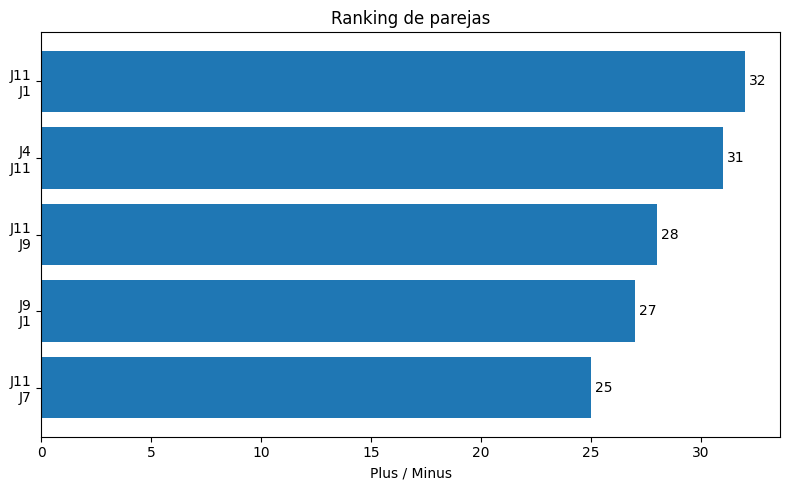

In [92]:
import matplotlib.pyplot as plt

# Top 5 parejas
top5 = df_resumen.head(5).copy()

# Etiquetas
top5["Pareja"] = (
    top5["Jugadora 1"] + "\n" +
    top5["Jugadora 2"]
)

plt.figure(figsize=(8,5))

bars = plt.barh(
    top5["Pareja"],
    top5["+/-"],
)

plt.gca().invert_yaxis()

for bar in bars:
    ancho = bar.get_width()
    plt.text(
        ancho + 0.2,
        bar.get_y() + bar.get_height()/2,
        f"{ancho:.0f}",
        va="center",
        fontsize=10
    )

plt.xlabel("Plus / Minus")
plt.title("Ranking de parejas")

plt.tight_layout()

plt.savefig(
    RUTA_RANKING,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**3 MEJORES PAREJAS**

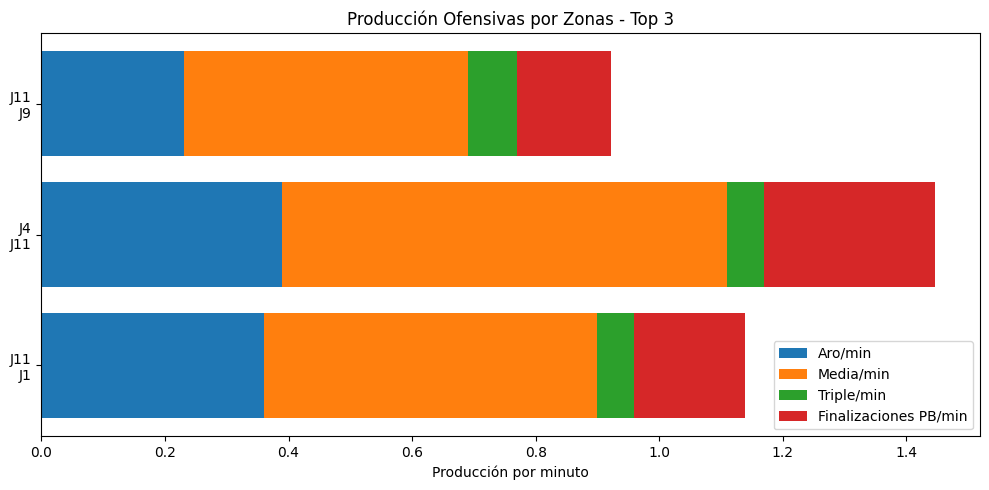

In [93]:
top3 = df_resumen.head(3).copy()

# Nombre de la pareja
top3["Pareja"] = (
    top3["Jugadora 1"] + "\n" + top3["Jugadora 2"]
)

plt.figure(figsize=(10,5))

plt.barh(
    top3["Pareja"],
    top3["Aro/min"],
    label="Aro/min"
)

plt.barh(
    top3["Pareja"],
    top3["Media/min"],
    left=top3["Aro/min"],
    label="Media/min"
)

plt.barh(
    top3["Pareja"],
    top3["Triple/min"],
    left=top3["Aro/min"] + top3["Media/min"],
    label="Triple/min"
)

plt.barh(
    top3["Pareja"],
    top3["Finalizaciones PB/min"],
    left=(
        top3["Aro/min"]
        + top3["Media/min"]
        + top3["Triple/min"]
    ),
    label="Finalizaciones PB/min"
)

plt.title("Producción Ofensivas por Zonas - Top 3")
plt.xlabel("Producción por minuto")
plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    RUTA_PRODUCCION,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**WORD AUTOMATICO**

importante!!!!!! **CAMBIAR MANUALMENTE EN CADA PARTIDO**

In [94]:
PARTIDO = " España vs I"
ID_PARTIDO= "131897"
FECHA= "xxxxxxxxx"

RUTA_LOGO= "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Logo.png"

crear word y cabecera

TENGO QUE configurar lso margenes y preparar la cabecera con el logo

In [95]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION

# Crear documento
doc = Document()

# Márgenes
seccion = doc.sections[0]
seccion.top_margin = Inches(0.6)
seccion.bottom_margin = Inches(0.6)
seccion.left_margin = Inches(0.7)
seccion.right_margin = Inches(0.7)

# Cabecera con logo
cabecera = seccion.header
parrafo_logo = cabecera.paragraphs[0]
parrafo_logo.alignment = WD_ALIGN_PARAGRAPH.CENTER

run_logo = parrafo_logo.add_run()
run_logo.add_picture(RUTA_LOGO, width=Inches(1.2))

# Título principal
titulo = doc.add_paragraph()
titulo.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = titulo.add_run("INFORME DE RENDIMIENTO DE PAREJAS")
run.bold = True
run.font.size = Pt(16)

# Datos del partido
datos = doc.add_paragraph()
datos.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = datos.add_run(
    f"{PARTIDO}\n"
    f"ID: {ID_PARTIDO} | Fecha: {FECHA}"
)
run.font.size = Pt(10)

print("Documento y cabecera creados correctamente")

Documento y cabecera creados correctamente


Para no poner todas las parejas, pongo una tabla de las 10 mejores

In [96]:
print(df_resumen.columns.tolist())

['Jugadora 1', 'Jugadora 2', 'Min', 'PF', 'PC', '+/-', 'Aro/min', 'Media/min', 'Triple/min', 'Finalizaciones PB/min']


In [97]:
# TABLA TOP 10 PAREJAS

doc.add_paragraph()

subtitulo = doc.add_paragraph()
subtitulo.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = subtitulo.add_run("RESUMEN DE LAS 10 MEJORES PAREJAS")
run.bold = True
run.font.size = Pt(12)

# Columnas reales del DataFrame
columnas_df = [
    "Jugadora 1",
    "Jugadora 2",
    "Min",
    "PF",
    "PC",
    "+/-",
    "Aro/min",
    "Media/min",
    "Finalizaciones PB/min"
]

# Encabezados que aparecerán en el Word
columnas_word = [
    "Jugadora 1",
    "Jugadora 2",
    "Min",
    "PF",
    "PC",
    "+/-",
    "ARO/min",
    "MEDIA/min",
    "PB/min"
]

tabla_word = df_resumen[columnas_df].head(10).copy()

# Crear tabla
tabla = doc.add_table(
    rows=1,
    cols=len(columnas_word)
)

tabla.style = "Table Grid"

# ==========================
# ENCABEZADOS
# ==========================

for i, columna in enumerate(columnas_word):

    celda = tabla.rows[0].cells[i]
    celda.text = columna

    for parrafo in celda.paragraphs:
        parrafo.alignment = WD_ALIGN_PARAGRAPH.CENTER

        for run in parrafo.runs:
            run.bold = True
            run.font.size = Pt(8)

# ==========================
# FILAS
# ==========================

for _, fila in tabla_word.iterrows():

    celdas = tabla.add_row().cells

    for i, columna in enumerate(columnas_df):

        valor = fila[columna]

        if columna == "Min":
            texto = f"{valor:.1f}"

        elif columna in ["PF", "PC", "+/-"]:
            texto = f"{int(valor)}"

        elif columna in [
            "Aro/min",
            "Media/min",
            "Finalizaciones PB/min"
        ]:
            texto = f"{valor:.2f}"

        else:
            texto = str(valor)

        celdas[i].text = texto

        for parrafo in celdas[i].paragraphs:
            parrafo.alignment = WD_ALIGN_PARAGRAPH.CENTER

            for run in parrafo.runs:
                run.font.size = Pt(8)

print("Tabla Top 10 añadida correctamente")

Tabla Top 10 añadida correctamente


**AÑADIR LOS GRÁFICOS**

In [98]:
# GRÁFICO 1 - RANKING DE PAREJAS

doc.add_paragraph()

subtitulo = doc.add_paragraph()
subtitulo.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = subtitulo.add_run("RANKING DE PAREJAS")
run.bold = True
run.font.size = Pt(12)

doc.add_picture(
    RUTA_RANKING,
    width=Inches(6.5)
)

ultimo = doc.paragraphs[-1]
ultimo.alignment = WD_ALIGN_PARAGRAPH.CENTER

print("Gráfico Ranking añadido al Word")


# LEYENDA
leyenda = doc.add_paragraph()
leyenda.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = leyenda.add_run(
    "PF = Puntos finalizados | "
    "PC = Puntos en contra | "
    "PB = Finalizaciones en poste bajo"
)

run.font.size = Pt(8)
run.italic = True

Gráfico Ranking añadido al Word


In [99]:
# GRÁFICO 2 - PRODUCCIÓN OFENSIVA POR ZONAS

doc.add_paragraph()

subtitulo = doc.add_paragraph()
subtitulo.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = subtitulo.add_run("PRODUCCIÓN OFENSIVA POR ZONAS - TOP 3")
run.bold = True
run.font.size = Pt(12)

doc.add_picture(
    RUTA_PRODUCCION,
    width=Inches(6.5)
)

ultimo = doc.paragraphs[-1]
ultimo.alignment = WD_ALIGN_PARAGRAPH.CENTER

print("Gráfico de Producción Ofensiva añadido al Word")

Gráfico de Producción Ofensiva añadido al Word


**GUARDAR INFORME**

In [100]:
import os

RUTA_INFORMES = "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Informes_parejas"
os.makedirs(RUTA_INFORMES, exist_ok=True)

nombre_archivo = f"Informe_{PARTIDO.replace(' ', '_')}.docx"
ruta_final = os.path.join(RUTA_INFORMES, nombre_archivo)

doc.save(ruta_final)

print("Informe guardado correctamente:")
print(ruta_final)


Informe guardado correctamente:
/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Informes_parejas/Informe__España_vs_I.docx


**CAMBIAR MANUALMENTEEEEEEEEE!!!!!!!!!!!**

In [101]:
NOMBRE_DATASET = "ESP_vs_I_131897"

In [102]:
# GUARDAR DATASET DE PAREJAS

ruta_dataset = "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Dataset_parejas"

nombre_csv = f"{NOMBRE_DATASET}.csv"

df_resumen.to_csv(
    f"{ruta_dataset}/{nombre_csv}",
    index=False,
    encoding="utf-8-sig"
)

print(" Dataset guardado correctamente")
print(f" {ruta_dataset}/{nombre_csv}")

 Dataset guardado correctamente
 /content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Dataset_parejas/ESP_vs_I_131897.csv
